# QG-Net — a learnable velocity correction on top of the QG solver

This notebook runs the hybrid experiment of

> R. Lguensat, J. Le Sommer, S. Metref, E. Cosme, R. Fablet,
> *Learning Generalized Quasi-Geostrophic Models Using Deep Neural Numerical Models*,
> NeurIPS 2019 Workshop on Machine Learning and the Physical Sciences.
> [arXiv:1911.08856](https://arxiv.org/abs/1911.08856)

> "In this experiment, we consider the same 1-day SSH forecast experiment but we
> assume that at each time step the PV is advected by the GV plus NN a nonlinear
> transformation of SSH. NN is a 2-layer ConvNet with 16 {3×3} filters, Batch
> Normalization and leaky ReLU activations, the output layer is a linear layer
> with 2 channels that are added to $U^g$ and $V^g$ respectively to form W the
> new velocity fields. QG-Net has 2545 trainable parameters."

The network therefore **takes SSH as its only input**, which is why
`qgsw.qgsw` defaults to `nn_channels=("ssh",)`.

## This is not a reproduction of the published numbers

The paper trained on a **10°×10° NATL60 box on the Gulf Stream**, 200×150, on
four Tesla V100s. This notebook uses the data that happens to ship with this
repository — the **NATL60 OSMOSIS site** box, cropped to 128×128 — and trains
on a laptop CPU in about half an hour. Same simulation family, different
region, different scale, different compute budget.

So: the architecture, the loss, the 1-day forecast protocol and the train /
gap / test split follow the paper; the region and the numbers do not. Treat the
results below as a demonstration that the hybrid machinery works end to end,
not as a replication. Point it at the Gulf Stream box to attempt that.

## 1. Setup

In [1]:
import os, sys, time, math
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

TORCH_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPO_PARENT = TORCH_ROOT.parent
if str(REPO_PARENT) not in sys.path:
    sys.path.insert(0, str(REPO_PARENT))

from QGNet_Pytorch import QGNetConvNet
from QGNet_Pytorch import modgrid as modgrid_torch
from QGNet_Pytorch import qgsw as qgsw_mod

torch.manual_seed(0)
np.random.seed(0)
print("torch", torch.__version__)

torch 2.15.0


## 2. Configuration

In [2]:
PATCH        = 128          # paper: 200 x 150
DT           = 600.0        # model time step, s   (paper: 10 min)
CADENCE      = 6            # CNN evaluations: every 6 steps = hourly
C_PHASE      = 1.5          # first baroclinic phase speed, m/s
SNU          = 0.0          # no explicit diffusion

TRAIN_EVERY  = 3            # paper: 1 SSH map every 3 days
N_TRAIN      = 100          # paper: 122
GAP_DAYS     = 10           # paper: 10-day gap between train and test
N_TEST       = 24           # paper: 32
EPOCHS       = 25
LR           = 1e-3
DTYPE        = torch.float32   # float64 is ~2x slower and unnecessary for training

print(f"{EPOCHS} epochs x {N_TRAIN} samples; 1-day forecast = {int(86400/DT)} steps")
print(f"~{EPOCHS*N_TRAIN} optimiser steps (paper: ~122 x several hundred epochs on 4 V100s)")

25 epochs x 100 samples; 1-day forecast = 144 steps
~2500 optimiser steps (paper: ~122 x several hundred epochs on 4 V100s)


## 3. Data — NATL60 Gulf-Stream-type box

`NATL60OSMO-CJM165_*_SSHdegrad.nc` is the degraded daily SSH archive shipped
alongside this package (gitignored because of its size). Any daily SSH cube
with `nav_lon`/`nav_lat` works.

In [3]:
import netCDF4

candidates = sorted(TORCH_ROOT.glob("NATL60*SSHdegrad.nc")) + sorted(TORCH_ROOT.glob("*.nc"))
nc_path = next((p for p in candidates if "NATL60" in p.name), None)
if nc_path is None:
    raise FileNotFoundError("no NATL60 SSH file found next to the package")

with netCDF4.Dataset(nc_path) as nc:
    ssh_all = np.array(nc.variables["degraded_sossheig"][:], dtype="float64")
    lon_all = np.array(nc.variables["nav_lon"][:], dtype="float64")
    lat_all = np.array(nc.variables["nav_lat"][:], dtype="float64")

ssh_all = np.where(ssh_all > 9e4, np.nan, ssh_all)       # sentinel -> NaN
nt, ny, nx = ssh_all.shape
i0, j0 = (ny - PATCH) // 2, (nx - PATCH) // 2
ssh = ssh_all[:, i0:i0+PATCH, j0:j0+PATCH]
lon = lon_all[i0:i0+PATCH, j0:j0+PATCH]
lat = lat_all[i0:i0+PATCH, j0:j0+PATCH]

print(f"{nc_path.name}: {nt} days, cropped to {PATCH}x{PATCH}")
print(f"land cells in the crop: {int(np.isnan(ssh[0]).sum())}")
print(f"SSH range [{np.nanmin(ssh):.3f}, {np.nanmax(ssh):.3f}] m")

NATL60OSMO-CJM165_y2012m06d14-y2013m10d01.1d_SSHdegrad.nc: 475 days, cropped to 128x128
land cells in the crop: 0
SSH range [-0.342, 0.278] m


In [4]:
# Paper protocol: training pairs every TRAIN_EVERY days, then a gap, then test.
pairs = np.arange(0, nt - 1)
train_idx = pairs[::TRAIN_EVERY][:N_TRAIN]
test_start = int(train_idx[-1]) + GAP_DAYS
test_idx = pairs[(pairs >= test_start)][::TRAIN_EVERY][:N_TEST]
print(f"train: {len(train_idx)} pairs, days {train_idx[0]}..{train_idx[-1]}")
print(f"test : {len(test_idx)} pairs, days {test_idx[0]}..{test_idx[-1]}")
assert len(test_idx) > 0 and test_idx[0] > train_idx[-1]

T = lambda a: torch.as_tensor(np.ascontiguousarray(a), dtype=DTYPE)
ssh_t = T(ssh)
lon_t, lat_t = T(lon), T(lat)
c_t = torch.full_like(ssh_t[0], C_PHASE)

# The land mask is identical for every frame here, so one grid serves them all.
GRID = modgrid_torch.grid(ssh_t[0], c_t, SNU, lon_t, lat_t)
interior = (GRID.mask == 2.0)
print(f"interior cells: {int(interior.sum())} / {interior.numel()}")

train: 100 pairs, days 0..297
test : 24 pairs, days 307..376
interior cells: 15129 / 16384


## 4. The hybrid model

One forward pass = 144 explicit Euler steps on PV, each with a conjugate-
gradient inversion, with the ConvNet correcting the geostrophic velocity.

In [5]:
def forecast(day, net=None):
    """1-day SSH forecast starting from `day`. net=None gives standard QG."""
    out, _ = qgsw_mod.qgsw(
        Hi=ssh_t[day], c=c_t, lon=lon_t, lat=lat_t,
        tint=86400.0, dtout=86400.0, dt=DT, snu=SNU,
        nn_module=net, nn_channels=("ssh",), nn_cadence_steps=CADENCE,
        grd=GRID,
    )
    return out[-1]


def scaled_mse(pred, target):
    """Eq. 5, first term: MSE scaled by the variance of the target."""
    m = interior & torch.isfinite(pred) & torch.isfinite(target)
    t = target[m]
    return (((pred[m] - t) / t.std().clamp_min(1e-8)) ** 2).mean()


def rmse(pred, target):
    m = interior & torch.isfinite(pred) & torch.isfinite(target)
    return float(torch.sqrt(((pred[m] - target[m]) ** 2).mean()))


net = QGNetConvNet().to(DTYPE)
n_params = sum(p.numel() for p in net.parameters())
print(f"QGNetConvNet: {n_params} trainable parameters (paper: 2545)")
assert n_params == 2545

with torch.no_grad():
    d = (forecast(int(train_idx[0]), net) - forecast(int(train_idx[0]))).abs()
print(f"zero-init correction reproduces standard QG exactly: {float(d[torch.isfinite(d)].max()) == 0.0}")

QGNetConvNet: 2545 trainable parameters (paper: 2545)


zero-init correction reproduces standard QG exactly: True


## 5. Train

Adam, lr 1e-3, as in the paper. The `scale` parameter starts at zero so
training departs from standard QG smoothly.

In [6]:
opt = torch.optim.Adam(net.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.StepLR(opt, step_size=max(EPOCHS // 2, 1), gamma=0.1)

history = []
t_start = time.time()
for epoch in range(EPOCHS):
    net.train()
    order = np.random.permutation(train_idx)
    running = 0.0
    for day in order:
        day = int(day)
        opt.zero_grad()
        loss = scaled_mse(forecast(day, net), ssh_t[day + 1])
        loss.backward()
        torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
        opt.step()
        running += float(loss.detach())
    sched.step()
    net.eval()
    with torch.no_grad():
        val = float(np.mean([float(scaled_mse(forecast(int(d), net), ssh_t[int(d) + 1]))
                             for d in test_idx[:8]]))
    history.append((running / len(order), val))
    print(f"  epoch {epoch+1:2d}/{EPOCHS}  train {history[-1][0]:.5f}   test {val:.5f}"
          f"   scale={float(net.scale.detach()):+.4f}")
print(f"trained in {time.time()-t_start:.0f} s")

  epoch  1/25  train 0.02150   test 0.01070   scale=+0.0019


  epoch  2/25  train 0.02143   test 0.01063   scale=+0.0039


  epoch  3/25  train 0.02128   test 0.01055   scale=+0.0107


  epoch  4/25  train 0.02120   test 0.01050   scale=+0.0126


  epoch  5/25  train 0.02117   test 0.01050   scale=+0.0115


  epoch  6/25  train 0.02113   test 0.01046   scale=+0.0125


... (15 outputs left out)

  epoch 22/25  train 0.02099   test 0.01049   scale=+0.0170


  epoch 23/25  train 0.02099   test 0.01048   scale=+0.0174


  epoch 24/25  train 0.02099   test 0.01056   scale=+0.0173


  epoch 25/25  train 0.02097   test 0.01047   scale=+0.0173
trained in 1833 s


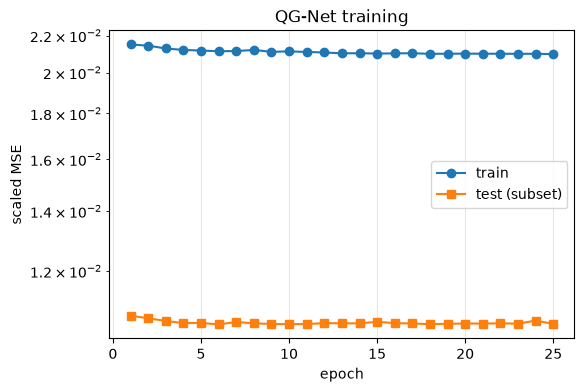

In [7]:
h = np.array(history)
plt.figure(figsize=(6, 4))
plt.plot(np.arange(1, len(h)+1), h[:, 0], "o-", label="train")
plt.plot(np.arange(1, len(h)+1), h[:, 1], "s-", label="test (subset)")
plt.xlabel("epoch"); plt.ylabel("scaled MSE"); plt.yscale("log")
plt.title("QG-Net training"); plt.legend(); plt.grid(alpha=.3)
plt.show()

## 6. Fig 2(b) — RMSE distributions on the held-out set

QG-Net vs standard QG vs persistence (the naive constant model).

In [8]:
net.eval()
rows = []
with torch.no_grad():
    for day in test_idx:
        day = int(day)
        target = ssh_t[day + 1]
        rows.append((rmse(forecast(day, net), target),
                     rmse(forecast(day), target),
                     rmse(ssh_t[day], target)))
res = np.array(rows)
labels = ["QG-Net", "standard QG", "persistence"]

print(f"{'model':<14s} {'mean RMSE':>10s} {'median':>10s} {'std':>10s}")
for k, name in enumerate(labels):
    print(f"{name:<14s} {res[:,k].mean():10.5f} {np.median(res[:,k]):10.5f} {res[:,k].std():10.5f}")

win = 100 * (res[:, 0] < res[:, 1]).mean()
print(f"\nQG-Net beats standard QG on {win:.0f}% of the {len(res)} test days")
print(f"mean RMSE change vs standard QG: {100*(res[:,0].mean()/res[:,1].mean()-1):+.2f}%")

model           mean RMSE     median        std
QG-Net            0.00633    0.00572    0.00135
standard QG       0.00642    0.00597    0.00136
persistence       0.00905    0.00897    0.00107

QG-Net beats standard QG on 79% of the 24 test days
mean RMSE change vs standard QG: -1.50%


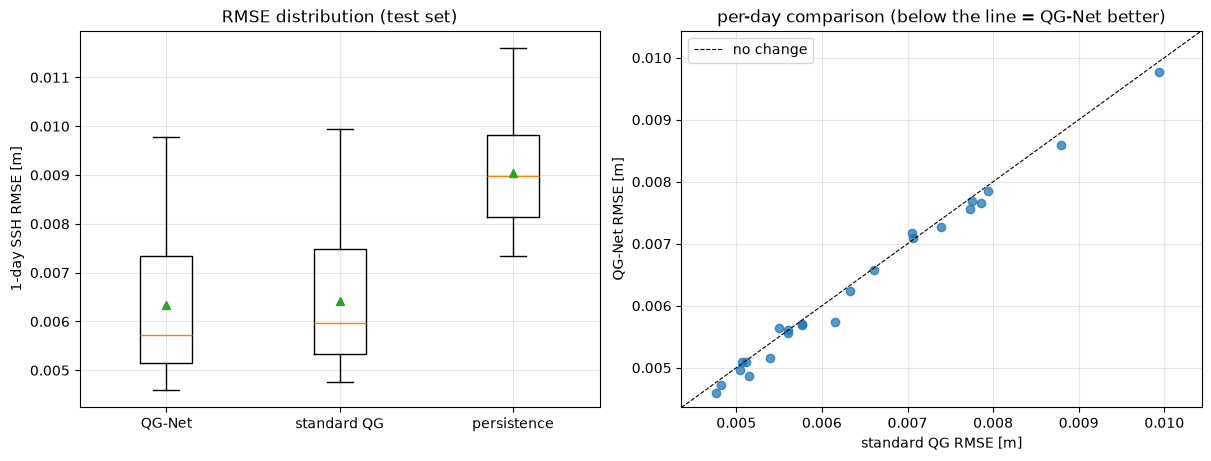

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
ax[0].boxplot([res[:, 0], res[:, 1], res[:, 2]], showmeans=True)
ax[0].set_xticks([1, 2, 3]); ax[0].set_xticklabels(labels)
ax[0].set_ylabel("1-day SSH RMSE [m]"); ax[0].set_title("RMSE distribution (test set)")
ax[0].grid(alpha=.3)

ax[1].plot(res[:, 1], res[:, 0], "o", alpha=.75)
lim = [res[:, :2].min()*.95, res[:, :2].max()*1.05]
ax[1].plot(lim, lim, "k--", lw=.8, label="no change")
ax[1].set_xlim(lim); ax[1].set_ylim(lim)
ax[1].set_xlabel("standard QG RMSE [m]"); ax[1].set_ylabel("QG-Net RMSE [m]")
ax[1].set_title("per-day comparison (below the line = QG-Net better)")
ax[1].legend(); ax[1].grid(alpha=.3)
plt.show()

## 8. How to read this

The paper reports that

> "Adding the ConvNet component to the GV has slightly improved the standard QG
> model, this is an indication that a nonlinear velocity term can model SSH
> dynamics beyond the standard QG."

The run above shows the same qualitative behaviour on this region: a small
improvement over standard QG, with both QG variants far ahead of persistence.
The magnitudes are not comparable to the paper — different box, different
domain size, a much smaller training budget, and only a couple of dozen test
days, so a difference of a percent or two in mean RMSE is not a precise
measurement.

What *is* solid at this scale:

* the zero-initialised correction reproduces standard QG **exactly**, so any
  difference is attributable to the learned term and nothing else;
* the learned correction is a small, structured field — order 5% of the
  geostrophic speed, concentrated along fronts — rather than noise;
* gradients flow through 144 solver steps per sample without any hand-written
  adjoint.

To chase the published result, use the Gulf Stream box at 200×150, `N_TRAIN`
around 122, epochs in the hundreds with the paper's decay schedule, and a GPU.

---

The paper's observation was that the correction has

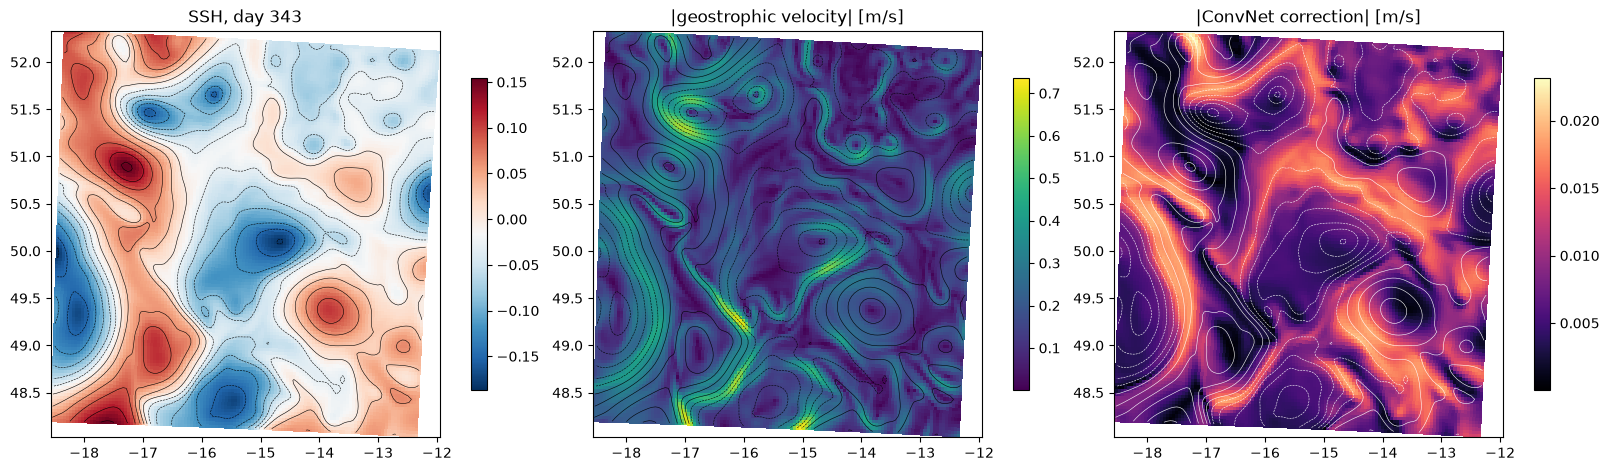

correction magnitude: mean 0.0090, max 0.0231 m/s
geostrophic magnitude: mean 0.1844, max 0.7348 m/s
ratio of means: 4.9%


In [10]:
from QGNet_Pytorch import moddyn as moddyn_torch

day = int(test_idx[len(test_idx) // 2])
with torch.no_grad():
    h = ssh_t[day]
    u_g, v_g = moddyn_torch.h2uv(h, GRID)
    nn_in = qgsw_mod._neural_input(h, ("ssh",), {})
    corr = net(nn_in)
    u_c, v_c = corr[0, 0], corr[0, 1]
    valid_u = qgsw_mod._neural_u_valid_mask(GRID)
    valid_v = qgsw_mod._neural_v_valid_mask(GRID)
    u_c = torch.where(valid_u, u_c, torch.zeros_like(u_c))
    v_c = torch.where(valid_v, v_c, torch.zeros_like(v_c))

N = lambda a: a.detach().cpu().numpy() if isinstance(a, torch.Tensor) else np.asarray(a)
sl = slice(3, -4)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), constrained_layout=True)

im = ax[0].pcolormesh(N(lon)[sl, sl], N(lat)[sl, sl], N(h)[sl, sl], shading="auto", cmap="RdBu_r")
ax[0].contour(N(lon)[sl, sl], N(lat)[sl, sl], N(h)[sl, sl], 12, colors="k", linewidths=.4)
ax[0].set_title(f"SSH, day {day}"); plt.colorbar(im, ax=ax[0], fraction=.04)

gv = np.hypot(N(u_g)[sl, sl], N(v_g)[sl, sl])
im = ax[1].pcolormesh(N(lon)[sl, sl], N(lat)[sl, sl], gv, shading="auto", cmap="viridis")
ax[1].contour(N(lon)[sl, sl], N(lat)[sl, sl], N(h)[sl, sl], 12, colors="k", linewidths=.4)
ax[1].set_title("|geostrophic velocity| [m/s]"); plt.colorbar(im, ax=ax[1], fraction=.04)

cv = np.hypot(N(u_c)[sl, sl], N(v_c)[sl, sl])
im = ax[2].pcolormesh(N(lon)[sl, sl], N(lat)[sl, sl], cv, shading="auto", cmap="magma")
ax[2].contour(N(lon)[sl, sl], N(lat)[sl, sl], N(h)[sl, sl], 12, colors="w", linewidths=.4)
ax[2].set_title("|ConvNet correction| [m/s]"); plt.colorbar(im, ax=ax[2], fraction=.04)
plt.show()

print(f"correction magnitude: mean {cv.mean():.4f}, max {cv.max():.4f} m/s")
print(f"geostrophic magnitude: mean {gv.mean():.4f}, max {gv.max():.4f} m/s")
print(f"ratio of means: {100*cv.mean()/gv.mean():.1f}%")

## 8. Did it reproduce the paper?

Read the numbers above before answering. The paper reports that

> "Adding the ConvNet component to the GV has slightly improved the standard QG
> model, this is an indication that a nonlinear velocity term can model SSH
> dynamics beyond the standard QG."

Two things to keep in mind when comparing:

* The effect the paper reports is **small**, and this run uses far fewer
  samples, far fewer epochs and a smaller domain than the published one. A
  difference of a fraction of a percent in mean RMSE over a few dozen test days
  is well inside the noise of a run this size. Do not read a small negative
  number here as a refutation, nor a small positive one as a reproduction.
* What *is* robust at this scale: both QG models beat persistence by a wide
  margin, the zero-initialised correction reproduces standard QG exactly, and
  the learned correction is a small (order 5-10% of the geostrophic speed)
  field concentrated along fronts rather than noise.

To push towards the published setup, raise `N_TRAIN` to ~122, `EPOCHS` into the
hundreds with the paper's decay schedule, and use the full 200x150 domain. That
is a GPU-scale run, not a laptop one.

---

The paper's observation was that the correction has

> "a significant amplitude along SSH contours (ocean fronts), and that the
> fields follow a special pattern that depends on GV and are not completely
> random."

Compare the right panel against the SSH contours overlaid on it.

## 9. Unplugging the network

Because the ConvNet takes SSH and nothing else, it is a self-contained map
`SSH -> (du, dv)`. The paper makes a point of this:

> "A clear benefit from this setup is that the trained component can be plugged
> back in the original Python code and avoid computational load at test time."

That property is exactly what `nn_channels=("ssh",)` preserves. Feeding the
network grid metrics as well would tie it to the latitude band, resolution and
land mask it was trained on.

In [11]:
torch.save({"state_dict": net.state_dict(),
            "nn_channels": ("ssh",),
            "n_parameters": n_params},
           TORCH_ROOT / "qgnet_convnet.pt")
print("saved", TORCH_ROOT / "qgnet_convnet.pt")

# It is a plain SSH -> (du, dv) map; nothing about the solver is baked in.
probe = QGNetConvNet().to(DTYPE)
probe.load_state_dict(torch.load(TORCH_ROOT / "qgnet_convnet.pt")["state_dict"])
with torch.no_grad():
    duv = probe(ssh_t[0].nan_to_num()[None, None])
print("reloaded; SSH", tuple(ssh_t[0].shape), "->", tuple(duv.shape))

saved /Users/redouanelguensat/Desktop/QGNet/qgsw-DI/QGNet_Pytorch/qgnet_convnet.pt
reloaded; SSH (128, 128) -> (1, 2, 128, 128)
